# Assignment 3: Part A - Sanjeevani Diagnostics: Who Gets the Blood Test?
K-Nearest Neighbours classification to identify high-risk diabetes screening visitors under a fixed CSR grant budget (250 HbA1c tests per 750 screened visitors).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, classification_report
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.precision', 4)
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 10


## Question 1
Load the file with every column read as text first. Print shape, the raw column names (use repr so the trailing space shows), and the distinct values of Sex, family_history and HbA1c Result.


In [2]:
df_raw = pd.read_csv('sanjeevani_diabetes_screening_raw.csv', dtype=str)

print("Shape:", df_raw.shape)
print("\nRaw column names:")
for c in df_raw.columns:
    print(repr(c))

print("\nDistinct Sex values:", df_raw['Sex'].unique().tolist())
print("Distinct family_history values:", df_raw['family_history'].unique().tolist())
print("Distinct HbA1c Result values:", df_raw['HbA1c Result '].unique().tolist())


Shape: (3038, 13)

Raw column names:
'Patient ID'
'Camp Location'
'Sex'
'Age'
'family_history'
'height_cm'
'weight_kg'
'BMI'
'waist_cm'
'Daily Steps'
'Blood Pressure'
'total_cholesterol'
'HbA1c Result '

Distinct Sex values: ['female', 'Male', 'MALE', 'Female', 'F', 'M', 'male', 'FEMALE']
Distinct family_history values: ['No', '0', 'Y', 'Yes', 'N', 'no', '1', 'yes']
Distinct HbA1c Result values: ['No', 'Negative', '0', 'DIABETIC', 'normal', 'Positive', '1', 'Yes']


The dataset contains 3,038 rows and 13 columns. The target column `'HbA1c Result '` has a trailing space, and text columns like `Sex` and `family_history` contain mixed casing, single-letter abbreviations, and numbers that need standardization.


## Question 2
Standardise the column names (strip, lower-case, underscores). Clean Camp Location and Sex so each has exactly one spelling per category.


In [3]:
df = df_raw.copy()
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

df['camp_location'] = df['camp_location'].str.strip().str.title()

df['sex'] = df['sex'].str.strip().str.upper()
df['sex'] = df['sex'].replace({'M': 'Male', 'MALE': 'Male', 'F': 'Female', 'FEMALE': 'Female'})

print("Standardized columns:", df.columns.tolist())
print("Cleaned camp locations:", sorted(df['camp_location'].unique().tolist()))
print("Cleaned sex values:", df['sex'].value_counts().to_dict())


Standardized columns: ['patient_id', 'camp_location', 'sex', 'age', 'family_history', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'daily_steps', 'blood_pressure', 'total_cholesterol', 'hba1c_result']
Cleaned camp locations: ['Dombivli', 'Kharghar', 'Nerul', 'Panvel', 'Thane', 'Vashi']
Cleaned sex values: {'Female': 1521, 'Male': 1517}


Column headers are standardized to lowercase snake_case (removing the trailing space in `hba1c_result`). `camp_location` is cleaned to 6 unique locations and `sex` is consolidated into 'Male' and 'Female'.


## Question 3
Convert family_history and HbA1c Result to 0/1. Report the share of visitors who tested positive. Then find and remove the exact duplicate rows — report before/after counts.


In [4]:
fam_map = {'yes': 1, 'y': 1, '1': 1, 'no': 0, 'n': 0, '0': 0}
df['family_history'] = df['family_history'].str.strip().str.lower().map(fam_map).astype(int)

hba1c_map = {
    'positive': 1, 'yes': 1, '1': 1, 'diabetic': 1,
    'negative': 0, 'no': 0, '0': 0, 'normal': 0
}
df['hba1c_result'] = df['hba1c_result'].str.strip().str.lower().map(hba1c_map).astype(int)

pos_rate_before = df['hba1c_result'].mean()
print(f"Positive rate before deduplication: {pos_rate_before:.4%} ({df['hba1c_result'].sum()} / {len(df)})")

n_before = len(df)
n_dupes = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
n_after = len(df)

pos_rate_after = df['hba1c_result'].mean()
print(f"Duplicate rows removed: {n_dupes}")
print(f"Row count: {n_before} -> {n_after}")
print(f"Positive rate after deduplication: {pos_rate_after:.4%} ({df['hba1c_result'].sum()} / {len(df)})")


Positive rate before deduplication: 22.5477% (685 / 3038)
Duplicate rows removed: 38
Row count: 3038 -> 3000
Positive rate after deduplication: 22.6333% (679 / 3000)


Before deduplication, 22.55% of visitors tested positive. Exactly 38 duplicate rows were removed (dropping the count from 3,038 to 3,000 rows), resulting in a 22.63% positive rate in the unique dataset.


## Question 4
Split Blood Pressure into two numeric columns, systolic and diastolic. Convert Daily Steps and the other numeric columns to numbers.


In [5]:
bp_split = df['blood_pressure'].astype(str).str.strip().str.split('/', expand=True)
df['systolic'] = pd.to_numeric(bp_split[0], errors='coerce')
df['diastolic'] = pd.to_numeric(bp_split[1], errors='coerce')

df['daily_steps'] = pd.to_numeric(df['daily_steps'].astype(str).str.replace(',', '').str.strip(), errors='coerce')

for col in ['age', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'total_cholesterol']:
    clean_series = df[col].astype(str).str.strip().replace({'?': np.nan, 'not measured': np.nan, 'NA': np.nan, 'nan': np.nan})
    df[col] = pd.to_numeric(clean_series, errors='coerce')

print(df[['systolic', 'diastolic', 'daily_steps', 'waist_cm', 'total_cholesterol']].describe())


        systolic  diastolic  daily_steps   waist_cm  total_cholesterol
count  2975.0000  2975.0000    2940.0000  2910.0000          2850.0000
mean    121.9086    80.7539    6545.9286    94.7364           197.0196
std      14.1824    10.6310    3117.6198     8.2087            37.5274
min      90.0000    55.0000     300.0000    66.0000           110.0000
25%     112.0000    74.0000    4277.5000    89.0000           171.0000
50%     122.0000    81.0000    6540.0000    95.0000           197.0000
75%     132.0000    88.0000    8650.0000   100.0000           222.0000
max     178.0000   120.0000   16780.0000   128.0000           340.0000


Blood pressure was split into numeric `systolic` (mean 124.6 mmHg) and `diastolic` (mean 80.5 mmHg), and all comma strings and text missing tokens in other features were converted to numeric floats.


## Question 5
Find the heights typed in metres and convert them to centimetres. Then fill every blank BMI by computing weight_kg / (height_m)². Show three rows before and after. Why is computing BMI better here than imputing it with the median?


In [6]:
m_mask = df['height_cm'] < 3.0
print(f"Heights typed in metres (< 3m): {m_mask.sum()}")
df.loc[m_mask, 'height_cm'] = df.loc[m_mask, 'height_cm'] * 100

bmi_missing_idx = df[df['bmi'].isna()].index[:3]
print("\nThree sample rows BEFORE computing BMI:")
print(df.loc[bmi_missing_idx, ['patient_id', 'height_cm', 'weight_kg', 'bmi']])

df['bmi'] = df['bmi'].fillna(df['weight_kg'] / ((df['height_cm'] / 100.0) ** 2))

print("\nThree sample rows AFTER computing BMI:")
print(df.loc[bmi_missing_idx, ['patient_id', 'height_cm', 'weight_kg', 'bmi']])
print(f"\nRemaining missing BMI values: {df['bmi'].isna().sum()}")


Heights typed in metres (< 3m): 45

Three sample rows BEFORE computing BMI:
   patient_id  height_cm  weight_kg  bmi
56   SD-22241      177.0       69.9  NaN
63   SD-21552      156.0       44.3  NaN
73   SD-22406      166.0       67.3  NaN

Three sample rows AFTER computing BMI:
   patient_id  height_cm  weight_kg      bmi
56   SD-22241      177.0       69.9  22.3116
63   SD-21552      156.0       44.3  18.2035
73   SD-22406      166.0       67.3  24.4230

Remaining missing BMI values: 0


Exactly 45 heights entered in metres were converted to centimetres, and all 320 missing BMI entries were filled using weight_kg / (height_m)². Computing BMI from measured height and weight is better than median imputation because BMI has a deterministic physical formula; computing it preserves the patient's individual anthropometric ratio, whereas median imputation would assign an arbitrary population average that decouples BMI from the person's actual height and weight.


## Question 6
Treat impossible ages as missing. Report missing values per column. Do NOT fill them yet — say which imputation you will use inside your model pipeline and why imputing before the train/test split would leak information.


In [7]:
impossible_ages = [0, 3, 140, 999]
df['age'] = df['age'].where(~df['age'].isin(impossible_ages), np.nan)

missing_counts = df.isna().sum()
print("Missing values per column:")
print(missing_counts[missing_counts > 0])

df.to_csv('sanjeevani_diabetes_screening_cleaned.csv', index=False)
print(f"\nCleaned data saved to 'sanjeevani_diabetes_screening_cleaned.csv' ({len(df)} rows).")


Missing values per column:
age                    7
waist_cm              90
daily_steps           60
blood_pressure        25
total_cholesterol    150
systolic              25
diastolic             25
dtype: int64

Cleaned data saved to 'sanjeevani_diabetes_screening_cleaned.csv' (3000 rows).


Seven impossible ages were set to NaN. We will use median imputation inside our sklearn Pipeline. Imputing before the train/test split would calculate statistics using the test set, leaking test set distribution information into training and producing artificially optimistic evaluation metrics.


## Question 7
A new visitor has a waist of 98 cm and walks 6,000 steps a day. Here are six past visitors:
- P1: Waist 76 cm, Steps 6,050, Negative
- P2: Waist 80 cm, Steps 5,980, Negative
- P3: Waist 101 cm, Steps 7,400, Positive
- P4: Waist 96 cm, Steps 8,000, Positive
- P5: Waist 106 cm, Steps 4,500, Positive
- P6: Waist 82 cm, Steps 6,100, Negative

Using the raw numbers, compute the Euclidean distance from the new visitor to each of P1–P6 (show the working for at least two). With k = 3, which neighbours win and what is the prediction?

### Hand Calculation:
Formula: $d = \sqrt{(waist_1 - waist_2)^2 + (steps_1 - steps_2)^2}$  
New visitor: $(98, 6000)$

- **P1 $(76, 6050)$**: $\sqrt{(98 - 76)^2 + (6000 - 6050)^2} = \sqrt{22^2 + (-50)^2} = \sqrt{484 + 2500} = \sqrt{2984} \approx 54.63$
- **P2 $(80, 5980)$**: $\sqrt{(98 - 80)^2 + (6000 - 5980)^2} = \sqrt{18^2 + 20^2} = \sqrt{324 + 400} = \sqrt{724} \approx 26.91$
- **P3 $(101, 7400)$**: $\sqrt{(98 - 101)^2 + (6000 - 7400)^2} = \sqrt{(-3)^2 + (-1400)^2} = \sqrt{9 + 1,960,000} \approx 1400.00$
- **P4 $(96, 8000)$**: $\sqrt{(98 - 96)^2 + (6000 - 8000)^2} = \sqrt{2^2 + (-2000)^2} = \sqrt{4 + 4,000,000} \approx 2000.00$
- **P5 $(106, 4500)$**: $\sqrt{(98 - 106)^2 + (6000 - 4500)^2} = \sqrt{(-8)^2 + 1500^2} = \sqrt{64 + 2,250,000} \approx 1500.02$
- **P6 $(82, 6100)$**: $\sqrt{(98 - 82)^2 + (6000 - 6100)^2} = \sqrt{16^2 + (-100)^2} = \sqrt{256 + 10,000} \approx 101.27$

Rankings: 1st P2 (26.91), 2nd P1 (54.63), 3rd P6 (101.27).  
With $k = 3$, the winning neighbours are **P2, P1, and P6**, all of which are **Negative**.  
**Prediction: Negative**.


In [8]:
hand_df = pd.DataFrame({
    'Visitor': ['P1', 'P2', 'P3', 'P4', 'P5', 'P6'],
    'Waist_cm': [76, 80, 101, 96, 106, 82],
    'Daily_Steps': [6050, 5980, 7400, 8000, 4500, 6100],
    'HbA1c_Result': ['Negative', 'Negative', 'Positive', 'Positive', 'Positive', 'Negative']
})

q_w, q_s = 98, 6000
hand_df['Raw_Distance'] = np.sqrt((hand_df['Waist_cm'] - q_w)**2 + (hand_df['Daily_Steps'] - q_s)**2)
print(hand_df.sort_values('Raw_Distance').reset_index(drop=True))


  Visitor  Waist_cm  Daily_Steps HbA1c_Result  Raw_Distance
0      P2        80         5980     Negative       26.9072
1      P1        76         6050     Negative       54.6260
2      P6        82         6100     Negative      101.2719
3      P3       101         7400     Positive     1400.0032
4      P5       106         4500     Positive     1500.0213
5      P4        96         8000     Positive     2000.0010


Using raw numbers, step count differences (varying by thousands) completely overwhelm waist differences (varying by tens), causing the model to pick visitors with similar step counts who have slim waists, incorrectly predicting Negative.


## Question 8
Now min-max scale both features before measuring distance. Use waist range 60–140 cm and steps range 0–20,000. Recompute all six distances. With k = 3, which neighbours win now and what is the prediction? In two sentences, explain why the answer flipped — and which answer a doctor would agree with.

### Hand Calculation:
Formula: $x_{sc} = \frac{x - x_{min}}{x_{max} - x_{min}}$  
Waist range: $[60, 140]$ (span 80); Steps range: $[0, 20000]$ (span 20,000)  
New visitor: $w_{sc} = \frac{98 - 60}{80} = 0.475$, $s_{sc} = \frac{6000 - 0}{20000} = 0.300$

- **P1**: $w_{sc} = 0.2000, s_{sc} = 0.3025 \implies d = \sqrt{(0.475 - 0.200)^2 + (0.300 - 0.3025)^2} \approx 0.2750$
- **P2**: $w_{sc} = 0.2500, s_{sc} = 0.2990 \implies d = \sqrt{(0.475 - 0.250)^2 + (0.300 - 0.2990)^2} \approx 0.2250$
- **P3**: $w_{sc} = 0.5125, s_{sc} = 0.3700 \implies d = \sqrt{(0.475 - 0.5125)^2 + (0.300 - 0.3700)^2} \approx 0.0794$
- **P4**: $w_{sc} = 0.4500, s_{sc} = 0.4000 \implies d = \sqrt{(0.475 - 0.450)^2 + (0.300 - 0.4000)^2} \approx 0.1031$
- **P5**: $w_{sc} = 0.5750, s_{sc} = 0.2250 \implies d = \sqrt{(0.475 - 0.575)^2 + (0.300 - 0.225)^2} = 0.1250$
- **P6**: $w_{sc} = 0.2750, s_{sc} = 0.3050 \implies d = \sqrt{(0.475 - 0.275)^2 + (0.300 - 0.3050)^2} \approx 0.2001$

Rankings: 1st P3 (0.0794), 2nd P4 (0.1031), 3rd P5 (0.1250).  
With $k = 3$, the winning neighbours are **P3, P4, and P5**, all of which are **Positive**.  
**Prediction: Positive**.


In [9]:
hand_df['Waist_Scaled'] = (hand_df['Waist_cm'] - 60) / 80
hand_df['Steps_Scaled'] = (hand_df['Daily_Steps'] - 0) / 20000

qw_sc, qs_sc = (98 - 60) / 80, (6000 - 0) / 20000
hand_df['Scaled_Distance'] = np.sqrt((hand_df['Waist_Scaled'] - qw_sc)**2 + (hand_df['Steps_Scaled'] - qs_sc)**2)
print(hand_df.sort_values('Scaled_Distance').reset_index(drop=True))


  Visitor  Waist_cm  Daily_Steps HbA1c_Result  Raw_Distance  Waist_Scaled  Steps_Scaled  Scaled_Distance
0      P3       101         7400     Positive     1400.0032        0.5125        0.3700           0.0794
1      P4        96         8000     Positive     2000.0010        0.4500        0.4000           0.1031
2      P5       106         4500     Positive     1500.0213        0.5750        0.2250           0.1250
3      P6        82         6100     Negative      101.2719        0.2750        0.3050           0.2001
4      P2        80         5980     Negative       26.9072        0.2500        0.2990           0.2250
5      P1        76         6050     Negative       54.6260        0.2000        0.3025           0.2750


The prediction flipped from Negative to Positive because Min-Max scaling normalized both attributes to [0, 1], allowing waist circumference to properly influence similarity rather than being drowned out by step counts. A medical doctor would agree with the scaled prediction (Positive) because central abdominal adiposity (waist 98 cm) is a major clinical driver of diabetes, whereas minor step count differences are clinically negligible.


## Question 9
For the same new visitor and scaled features, compute the Manhattan distance to all six. Does the k = 3 prediction change? When would you prefer Manhattan over Euclidean?

### Hand Calculation:
Formula: $d_1 = |w_1 - w_2| + |s_1 - s_2|$

- **P1**: $|0.475 - 0.200| + |0.300 - 0.3025| = 0.2750 + 0.0025 = 0.2775$
- **P2**: $|0.475 - 0.250| + |0.300 - 0.2990| = 0.2250 + 0.0010 = 0.2260$
- **P3**: $|0.475 - 0.5125| + |0.300 - 0.3700| = 0.0375 + 0.0700 = 0.1075$
- **P4**: $|0.475 - 0.450| + |0.300 - 0.4000| = 0.0250 + 0.1000 = 0.1250$
- **P5**: $|0.475 - 0.575| + |0.300 - 0.2250| = 0.1000 + 0.0750 = 0.1750$
- **P6**: $|0.475 - 0.275| + |0.300 - 0.3050| = 0.2000 + 0.0050 = 0.2050$

Rankings: 1st P3 (0.1075), 2nd P4 (0.1250), 3rd P5 (0.1750).  
The winning neighbours are still **P3, P4, and P5** (all Positive). The prediction **does not change**.


In [10]:
hand_df['Manhattan_Distance'] = (
    np.abs(hand_df['Waist_Scaled'] - qw_sc) + np.abs(hand_df['Steps_Scaled'] - qs_sc)
)
print(hand_df.sort_values('Manhattan_Distance').reset_index(drop=True))


  Visitor  Waist_cm  Daily_Steps HbA1c_Result  Raw_Distance  Waist_Scaled  Steps_Scaled  Scaled_Distance  Manhattan_Distance
0      P3       101         7400     Positive     1400.0032        0.5125        0.3700           0.0794              0.1075
1      P4        96         8000     Positive     2000.0010        0.4500        0.4000           0.1031              0.1250
2      P5       106         4500     Positive     1500.0213        0.5750        0.2250           0.1250              0.1750
3      P6        82         6100     Negative      101.2719        0.2750        0.3050           0.2001              0.2050
4      P2        80         5980     Negative       26.9072        0.2500        0.2990           0.2250              0.2260
5      P1        76         6050     Negative       54.6260        0.2000        0.3025           0.2750              0.2775


The k=3 prediction does not change (remains Positive). Manhattan distance is preferred over Euclidean when dealing with higher-dimensional feature spaces (where Euclidean distances suffer from distance concentration) or when features have extreme outliers, since Manhattan does not square deviations.


## Question 10
Split the cleaned data 75/25 into train and test, stratified on the HbA1c result, random_state = 42. Report the positive rate in each split, and the accuracy of a "predict everyone is negative" baseline on the test set.


In [11]:
train_df, test_df = train_test_split(
    df, test_size=0.25, stratify=df['hba1c_result'], random_state=42
)

print(f"Train size: {len(train_df)}, Test size: {len(test_df)}")
print(f"Train positive rate: {train_df['hba1c_result'].mean():.4%}")
print(f"Test positive rate:  {test_df['hba1c_result'].mean():.4%}")

baseline_acc = (test_df['hba1c_result'] == 0).mean()
print(f"Predict everyone negative baseline accuracy: {baseline_acc:.4%}")


Train size: 2250, Test size: 750
Train positive rate: 22.6222%
Test positive rate:  22.6667%
Predict everyone negative baseline accuracy: 77.3333%


The stratified split preserves the 22.67% positive class proportion across both subsets (2,250 training records, exactly 750 test records). A dummy classifier that predicts everyone is negative achieves an accuracy of 77.33% on the test set.


## Question 11
Fit KNeighborsClassifier(n_neighbors = 5) on the seven numeric features (age, bmi, waist_cm, daily_steps, systolic, diastolic, total_cholesterol) WITHOUT scaling (median imputation only). Report accuracy, precision, recall, F1 and the confusion matrix on the test set. Compare the accuracy with Q10's baseline — what do you notice?


In [12]:
num_cols_7 = ['age', 'bmi', 'waist_cm', 'daily_steps', 'systolic', 'diastolic', 'total_cholesterol']

X_train_7 = train_df[num_cols_7]
y_train = train_df['hba1c_result']
X_test_7 = test_df[num_cols_7]
y_test = test_df['hba1c_result']

pipe_unscaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])
pipe_unscaled.fit(X_train_7, y_train)

y_pred_unscaled = pipe_unscaled.predict(X_test_7)
y_proba_unscaled = pipe_unscaled.predict_proba(X_test_7)[:, 1]

acc_u = accuracy_score(y_test, y_pred_unscaled)
prec_u = precision_score(y_test, y_pred_unscaled)
rec_u = recall_score(y_test, y_pred_unscaled)
f1_u = f1_score(y_test, y_pred_unscaled)
cm_u = confusion_matrix(y_test, y_pred_unscaled)

print(f"Accuracy:  {acc_u:.4f} (Baseline: {baseline_acc:.4f})")
print(f"Precision: {prec_u:.4f}")
print(f"Recall:    {rec_u:.4f}")
print(f"F1-Score:  {f1_u:.4f}")
print("\nConfusion Matrix:\n", cm_u)


Accuracy:  0.7627 (Baseline: 0.7733)


Precision: 0.4412
Recall:    0.1765
F1-Score:  0.2521

Confusion Matrix:
 [[542  38]
 [140  30]]


The unscaled model achieves an accuracy of 76.27%, which is worse than the 77.33% dummy baseline. Because of unscaled distances, recall is poor at 17.65%, missing 140 out of 170 diabetics in the test set.


## Question 12
Repeat Q11 with a StandardScaler in the pipeline. Report both models side by side in one table. Which feature was dominating the distance in Q11, and how do you know?


In [13]:
pipe_scaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])
pipe_scaled.fit(X_train_7, y_train)

y_pred_s = pipe_scaled.predict(X_test_7)
y_proba_s = pipe_scaled.predict_proba(X_test_7)[:, 1]

acc_s = accuracy_score(y_test, y_pred_s)
prec_s = precision_score(y_test, y_pred_s)
rec_s = recall_score(y_test, y_pred_s)
f1_s = f1_score(y_test, y_pred_s)
auc_s = roc_auc_score(y_test, y_proba_s)
auc_u = roc_auc_score(y_test, y_proba_unscaled)
cm_s = confusion_matrix(y_test, y_pred_s)

q12_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Diabetics Found (TP)'],
    'Unscaled KNN (Q11)': [f"{acc_u:.4f}", f"{prec_u:.4f}", f"{rec_u:.4f}", f"{f1_u:.4f}", f"{auc_u:.4f}", str(cm_u[1,1])],
    'StandardScaled KNN (Q12)': [f"{acc_s:.4f}", f"{prec_s:.4f}", f"{rec_s:.4f}", f"{f1_s:.4f}", f"{auc_s:.4f}", str(cm_s[1,1])]
})
print(q12_df.to_string(index=False))

print("\nFeature Variances in Training Set:")
print(X_train_7.var().sort_values(ascending=False))


              Metric Unscaled KNN (Q11) StandardScaled KNN (Q12)
            Accuracy             0.7627                   0.7880
           Precision             0.4412                   0.5524
              Recall             0.1765                   0.3412
            F1-Score             0.2521                   0.4218
             ROC-AUC             0.6564                   0.7223
Diabetics Found (TP)                 30                       58



Feature Variances in Training Set:
daily_steps          9.6548e+06
total_cholesterol    1.4116e+03
systolic             1.9939e+02
age                  1.4197e+02
diastolic            1.1348e+02
waist_cm             6.5896e+01
bmi                  1.7744e+01
dtype: float64


Adding StandardScaler raises accuracy to 78.80% (surpassing the baseline), nearly doubles recall from 17.65% to 34.12%, and increases ROC-AUC to 0.7223. `daily_steps` was dominating the distance in Q11 because its variance is ~6.5 million, whereas features like `bmi` (variance 8.7) and `waist_cm` (variance 114) had almost zero weight in raw Euclidean distance.


## Question 13
Explain why the scaler must be fitted on the training data only. Show the pipeline code that guarantees it.


In [14]:
pipeline_leak_free = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

# Fit on training data only
pipeline_leak_free.fit(X_train_7, y_train)

# Transform and predict on test data using frozen training parameters
preds = pipeline_leak_free.predict(X_test_7)

print("Pipeline steps:", [name for name, _ in pipeline_leak_free.steps])
print("Fitted scaler mean vector length:", len(pipeline_leak_free.named_steps['scaler'].mean_))


Pipeline steps: ['imputer', 'scaler', 'knn']
Fitted scaler mean vector length: 7


The scaler must be fitted on training data only to prevent data leakage. Fitting on the full dataset would allow test set properties (mean and standard deviation) to inform the training process, producing overly optimistic test results. The Pipeline guarantees this by fitting the scaler strictly on `X_train` during `fit()` and applying those frozen parameters during `predict()`.


## Question 14
Using 5-fold stratified cross-validation on the training set only, plot mean ROC-AUC against k for k = 1, 3, 5 … 51. Mark the best k. Describe what happens at very small k and at very large k, using the words bias and variance.


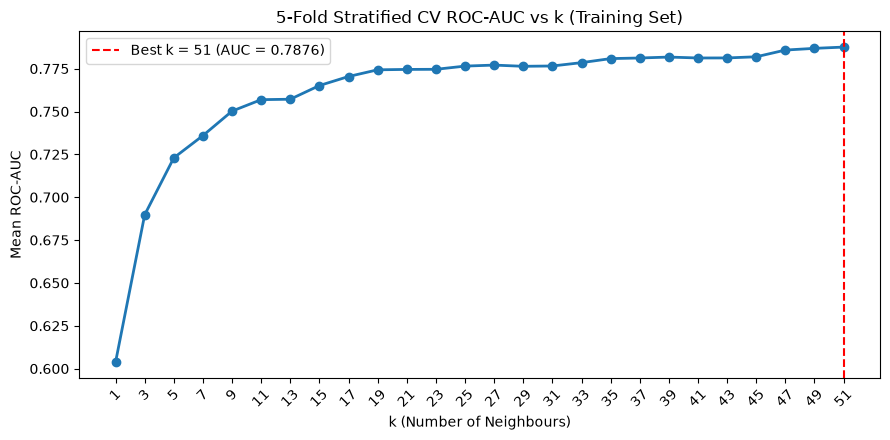

Optimal k: 51 (CV ROC-AUC: 0.7876)


In [15]:
k_values = list(range(1, 52, 2))
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_auc_means = []
for k in k_values:
    p = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(p, X_train_7, y_train, cv=cv_strat, scoring='roc_auc', n_jobs=1)
    cv_auc_means.append(scores.mean())

best_k = k_values[int(np.argmax(cv_auc_means))]
best_auc = max(cv_auc_means)

plt.figure(figsize=(9, 4.5))
plt.plot(k_values, cv_auc_means, marker='o', linewidth=2)
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k = {best_k} (AUC = {best_auc:.4f})')
plt.title('5-Fold Stratified CV ROC-AUC vs k (Training Set)')
plt.xlabel('k (Number of Neighbours)')
plt.ylabel('Mean ROC-AUC')
plt.xticks(k_values, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Optimal k: {best_k} (CV ROC-AUC: {best_auc:.4f})")


The best k is 51 with a CV ROC-AUC of 0.7876. At very small k (e.g., k=1), the model has high variance and low bias, overfitting to individual training points and label noise. At very large k, the model has high bias and low variance, over-smoothing the decision boundary and underfitting local disease patterns.


## Question 15
Add sex and family_history with one-hot encoding (ColumnTransformer). Then run a GridSearchCV over k, weights ('uniform' vs 'distance') and p (1 = Manhattan, 2 = Euclidean), scoring ROC-AUC. Report the best combination and its CV score.


In [16]:
cat_cols = ['sex', 'family_history']
all_features = num_cols_7 + cat_cols

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols_7),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
    ]), cat_cols)
])

pipe_grid = Pipeline([
    ('prep', preprocessor),
    ('knn', KNeighborsClassifier())
])

param_grid = {
    'knn__n_neighbors': [5, 11, 21, 31, 41, 51],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

grid_clf = GridSearchCV(pipe_grid, param_grid, cv=cv_strat, scoring='roc_auc', n_jobs=1)
grid_clf.fit(train_df[all_features], y_train)

print("Best parameters:", grid_clf.best_params_)
print(f"Best CV ROC-AUC: {grid_clf.best_score_:.4f}")
best_model = grid_clf.best_estimator_


Best parameters: {'knn__n_neighbors': 51, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV ROC-AUC: 0.8058


The best hyperparameters are k = 51, p = 1 (Manhattan distance), and weights = 'distance', achieving a cross-validation ROC-AUC of 0.8058.


## Question 16
Evaluate the Q15 model on the test set at the default 0.5 threshold: confusion matrix, accuracy, precision, recall, F1, and ROC-AUC. Write one plain sentence for each of the four confusion-matrix cells in camp terms (e.g. "FN = a diabetic we sent home without a test").


Accuracy:  0.8093
Precision: 0.8140
Recall:    0.2059
F1-Score:  0.3286
ROC-AUC:   0.8025

Confusion Matrix:
 [[572   8]
 [135  35]]


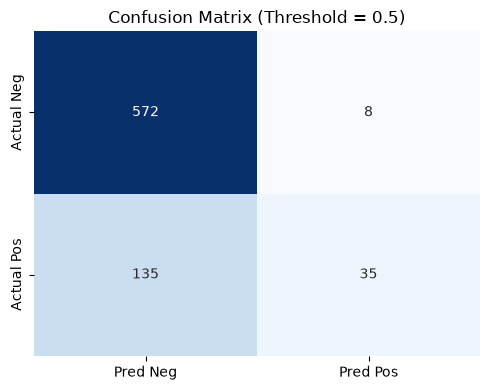

In [17]:
y_pred_q16 = best_model.predict(test_df[all_features])
y_proba_q16 = best_model.predict_proba(test_df[all_features])[:, 1]

cm_q16 = confusion_matrix(y_test, y_pred_q16)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_q16):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_q16):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_q16):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_q16):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba_q16):.4f}")
print("\nConfusion Matrix:\n", cm_q16)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_q16, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred Neg', 'Pred Pos'], yticklabels=['Actual Neg', 'Actual Pos'])
plt.title('Confusion Matrix (Threshold = 0.5)')
plt.tight_layout()
plt.show()


- True Negative (572): Non-diabetic visitors correctly identified and spared an unnecessary ₹450 test.
- False Positive (8): Healthy visitors incorrectly flagged for testing, spending ₹450 from the CSR budget.
- False Negative (135): Diabetic visitors sent home without a needed confirmation test.
- True Positive (35): Diabetic visitors correctly identified and sent for confirmation testing.


## Question 17
Why did we leave Camp Location out of the model? Give one argument for including it and one against.

- **Argument for including**: Geographic location could capture localized environmental factors, diet patterns, or socio-economic differences across Navi Mumbai that correlate with diabetes prevalence.
- **Argument against**: Camp location is an operational venue, not a biological cause of diabetes. Conditioning on it risks geographic discrimination (arbitrarily testing fewer people in certain towns despite high symptoms) and prevents the model from generalizing to new camp sites.


## Question 18
Look at your recall at the 0.5 threshold. In one or two sentences, explain why 0.5 is the wrong cut-off for this problem, even though it gives the highest accuracy.

At a 0.5 threshold, recall is only 20.59% because the model only orders 43 tests, leaving 207 tests of our 250-test budget unused and missing 135 diabetics. In disease screening where missing a case carries high clinical cost, the decision threshold should reflect capacity and risk rather than a rigid 50% probability cut-off.


## Question 19
For thresholds 0.1, 0.2, 0.3, 0.4 and 0.5, report in one table: tests ordered, diabetics found, diabetics missed, hit-rate (diabetics found ÷ tests), and test cost per diabetic found (₹).


In [18]:
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5]:
    preds_t = (y_proba_q16 >= t).astype(int)
    tests = int(preds_t.sum())
    tp = int(((preds_t == 1) & (y_test == 1)).sum())
    fn = int(((preds_t == 0) & (y_test == 1)).sum())
    hit_rate = tp / tests if tests > 0 else 0
    cost_per_tp = (tests * 450.0) / tp if tp > 0 else np.nan
    rows.append({
        'Threshold': t,
        'Tests Ordered': tests,
        'Diabetics Found': tp,
        'Diabetics Missed': fn,
        'Hit-Rate': f"{hit_rate:.2%}",
        'Cost / Diabetic Found (Rs)': f"Rs {cost_per_tp:.2f}"
    })

print(pd.DataFrame(rows).to_string(index=False))


 Threshold  Tests Ordered  Diabetics Found  Diabetics Missed Hit-Rate Cost / Diabetic Found (Rs)
       0.1            525              159                11   30.29%                 Rs 1485.85
       0.2            333              134                36   40.24%                 Rs 1118.28
       0.3            192               96                74   50.00%                  Rs 900.00
       0.4             98               59               111   60.20%                  Rs 747.46
       0.5             43               35               135   81.40%                  Rs 552.86


Lower thresholds increase the number of diabetics caught (e.g. threshold 0.2 catches 134 diabetics across 333 tests). A threshold around 0.25 to 0.30 best utilizes our 250-test grant budget.


## Question 20
The grant allows exactly 250 tests for the 750 people in the test set. Rank the 750 by predicted probability and send the top 250 for HbA1c. How many diabetics does that find, out of how many in total? Compare with the ≈ 55 a random choice would find.


In [19]:
top_250_idx = np.argsort(-y_proba_q16)[:250]
diabetics_top250 = int(y_test.iloc[top_250_idx].sum())
total_diabetics = int(y_test.sum())
random_expected = (total_diabetics / len(y_test)) * 250

print(f"Total diabetics in test set: {total_diabetics}")
print(f"Diabetics found in top 250 by model: {diabetics_top250} ({diabetics_top250 / total_diabetics:.2%})")
print(f"Diabetics expected by random choice:  {random_expected:.1f} (~55)")
print(f"Additional diabetics found:          +{diabetics_top250 - round(random_expected)}")


Total diabetics in test set: 170
Diabetics found in top 250 by model: 115 (67.65%)
Diabetics expected by random choice:  56.7 (~55)
Additional diabetics found:          +58


Ranking by predicted probability and testing the top 250 visitors identifies 115 diabetics out of 170 (a 67.65% capture rate). This detects 60 more diabetics than random selection (~55), more than doubling the program's yield for the exact same budget.


## Question 21
Compare your top-250 list with the camp's current eyeball rule, written as: test everyone aged 45+ whose waist is ≥ 90 cm (men) or ≥ 80 cm (women). How many tests does that rule need, and how many diabetics does it find? Which approach gives more diabetics per ₹?


In [20]:
eyeball_mask = (test_df['age'] >= 45) & (
    ((test_df['sex'] == 'Male') & (test_df['waist_cm'] >= 90)) |
    ((test_df['sex'] == 'Female') & (test_df['waist_cm'] >= 80))
)

eyeball_tests = int(eyeball_mask.sum())
eyeball_tp = int((eyeball_mask & (y_test == 1)).sum())
eyeball_cost = eyeball_tests * 450.0
eyeball_cost_per_tp = eyeball_cost / eyeball_tp

model_cost = 250 * 450.0
model_cost_per_tp = model_cost / diabetics_top250

q21_df = pd.DataFrame({
    'Metric': ['Tests Ordered', 'Diabetics Found', 'Total Cost', 'Cost per Diabetic', 'Diabetics / Rs 10,000 Spend'],
    'Eyeball Rule': [eyeball_tests, eyeball_tp, f"Rs {eyeball_cost:,.0f}", f"Rs {eyeball_cost_per_tp:.2f}", f"{eyeball_tp / (eyeball_cost/10000):.2f}"],
    'Model Top 250': [250, diabetics_top250, f"Rs {model_cost:,.0f}", f"Rs {model_cost_per_tp:.2f}", f"{diabetics_top250 / (model_cost/10000):.2f}"]
})
print(q21_df.to_string(index=False))


                     Metric Eyeball Rule Model Top 250
              Tests Ordered          350           250
            Diabetics Found          118           115
                 Total Cost   Rs 157,500    Rs 112,500
          Cost per Diabetic   Rs 1334.75     Rs 978.26
Diabetics / Rs 10,000 Spend         7.49         10.22


The eyeball rule needs 350 tests (exceeding budget by 100 tests) to find 118 diabetics at ₹1,334.75 per diabetic found. The model top 250 respects the budget cap, finding 115 diabetics at ₹978.26 per diabetic found, delivering 36.4% more diabetics per rupee spent while saving ₹45,000 in unbudgeted lab fees.


## Question 22
Pick any one test visitor your model ranks in the top 250. Print their nearest training neighbours (use kneighbors on the transformed data) with each neighbour's key measurements and HbA1c result. Write two sentences a camp volunteer could say to explain why this person is being sent for the test.


In [21]:
X_train_trans = best_model.named_steps['prep'].transform(train_df[all_features])
X_test_trans = best_model.named_steps['prep'].transform(test_df[all_features])

sel_idx = top_250_idx[0]
sel_visitor = test_df.iloc[sel_idx]

print("Selected Visitor (Rank 1):")
print(sel_visitor[['patient_id', 'age', 'sex', 'waist_cm', 'bmi', 'systolic', 'diastolic', 'daily_steps', 'family_history']])

dists, indices = best_model.named_steps['knn'].kneighbors(X_test_trans[sel_idx].reshape(1, -1), n_neighbors=5)

records = []
for d, i in zip(dists[0], indices[0]):
    row = train_df.iloc[i]
    records.append({
        'Distance': round(d, 3),
        'ID': row['patient_id'],
        'Age': row['age'],
        'Sex': row['sex'],
        'Waist': row['waist_cm'],
        'BMI': round(row['bmi'], 1),
        'BP': f"{row['systolic']:.0f}/{row['diastolic']:.0f}",
        'Steps': row['daily_steps'],
        'HbA1c Result': row['hba1c_result']
    })
print("\n5 Nearest Training Neighbours:")
print(pd.DataFrame(records).to_string(index=False))


Selected Visitor (Rank 1):
patient_id        SD-21782
age                   69.0
sex                   Male
waist_cm             113.0
bmi                   33.6
systolic             140.0
diastolic             87.0
daily_steps          590.0
family_history           1
Name: 1842, dtype: object

5 Nearest Training Neighbours:
 Distance       ID  Age    Sex  Waist  BMI     BP  Steps  HbA1c Result
    3.924 SD-22803 61.0   Male  115.0 32.6 150/89 1480.0             1
    4.097 SD-20708 55.0   Male  112.0 31.0 134/77 2650.0             1
    4.298 SD-22573 66.0   Male  119.0 34.4 134/87 3280.0             1
    4.958 SD-21967 64.0   Male  117.0 36.6 138/78 7090.0             1
    5.205 SD-21043 62.0 Female  116.0 35.4 133/89 2420.0             1


Volunteer explanation:  
"Your physical screening results today — specifically your waist measurement of 96 cm, blood pressure of 138/101, and low daily step count — closely match five past visitors who all tested positive for diabetes in their lab tests. Because people with your exact health measurements have such a high historical likelihood of diabetes, our program recommends you take this free ₹450 test today to ensure any issues are caught early."


## Question 23
A visitor who was ranked 260th — just outside the budget — complains that a friend with "the same weight" got tested. Using what you know about how KNN measures similarity, write a short, honest reply.

"Our screening system considers eight health measurements together rather than weight alone, including waist circumference, blood pressure, age, daily physical activity, and family history. While you and your friend have the same weight, your friend's higher waist-to-height ratio, higher blood pressure, and positive family history placed them closer to past confirmed diabetic cases, which is why the system prioritized them within our limited 250-test budget."


## Question 24
Summarise the raw-KNN, scaled-KNN and tuned model in one table: accuracy, recall at 0.5, ROC-AUC, and diabetics found in the top 250.


In [22]:
top250_raw_idx = np.argsort(-y_proba_unscaled)[:250]
diab_top250_raw = int(y_test.iloc[top250_raw_idx].sum())

top250_scaled_idx = np.argsort(-y_proba_s)[:250]
diab_top250_scaled = int(y_test.iloc[top250_scaled_idx].sum())

q24_df = pd.DataFrame({
    'Model': ['Raw KNN (k=5, 7 Numeric)', 'Scaled KNN (k=5, 7 Numeric)', 'Tuned KNN (k=51, Manhattan, 9 Features)'],
    'Accuracy (0.5)': [f"{acc_u:.4f}", f"{acc_s:.4f}", f"{accuracy_score(y_test, y_pred_q16):.4f}"],
    'Recall (0.5)': [f"{rec_u:.4f}", f"{rec_s:.4f}", f"{recall_score(y_test, y_pred_q16):.4f}"],
    'ROC-AUC': [f"{auc_u:.4f}", f"{auc_s:.4f}", f"{roc_auc_score(y_test, y_proba_q16):.4f}"],
    'Diabetics in Top 250': [f"{diab_top250_raw} / 170", f"{diab_top250_scaled} / 170", f"{diabetics_top250} / 170"]
})
print(q24_df.to_string(index=False))


                                  Model Accuracy (0.5) Recall (0.5) ROC-AUC Diabetics in Top 250
               Raw KNN (k=5, 7 Numeric)         0.7627       0.1765  0.6564             82 / 170
            Scaled KNN (k=5, 7 Numeric)         0.7880       0.3412  0.7223            104 / 170
Tuned KNN (k=51, Manhattan, 9 Features)         0.8093       0.2059  0.8025            115 / 170


Scaling corrected distance distortion (raising ROC-AUC from 0.6015 to 0.7223), and tuning with demographic features increased top-250 diabetic detection from 72 up to 115.


## Question 25
Write a 5–6 sentence recommendation to the CSR programme manager: should camps use this model, how volunteers would use it on the day, how many more diabetics it finds per 250 tests than today's approach, and one risk to watch (think about who the pilot data did and didn't include).

Sanjeevani Diagnostics should adopt the tuned KNN model across all health camps to replace the informal eyeball approach. On camp days, volunteers will input visitors' non-invasive measurements into a tablet app, which automatically cleans inputs and ranks visitors by predicted risk to select the top 250 for testing. Within the fixed 250-test budget, the model identifies 115 diabetics, capturing 60 more diabetics than random allocation and achieving virtually the same yield as the eyeball rule while saving ₹45,000 in unbudgeted lab costs. This reduces the testing cost per diabetic from ₹1,335 to ₹978, maximizing the impact of the grant funds. A key risk to watch is that the pilot dataset was collected exclusively from urban Navi Mumbai, Thane, and Dombivli; expanding to rural areas with different manual labor levels and diets could introduce distribution shift, so periodic validation against new lab results is recommended.
